# ĐỒ ÁN 
![Quy trình tổng thể](../figures/00_quy_trinh_tong_the.png)


---
#  STEP 1 - ĐỊNH NGHĨA BÀI TOÁN & KHẢO SÁT DỮ LIỆU 

#### 1.1 Khai báo thư viện & Cấu hình biểu đồ

In [1]:
import os
os.makedirs('../figures', exist_ok=True)
os.makedirs('../datas', exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình hiển thị đồ họa
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
print("Nạp thư viện thành công!")

Nạp thư viện thành công!


#### 1.2 Đọc dữ liệu & Xem kích thước (shape)

In [2]:
# Đọc file dữ liệu gốc từ thư mục datas
df_raw = pd.read_csv('../datas/laptop_price - dataset.csv') 
print(f"Kích thước dữ liệu gốc: {df_raw.shape[0]:,} dòng (mẫu laptop), {df_raw.shape[1]} cột (thuộc tính)")

Kích thước dữ liệu gốc: 1,275 dòng (mẫu laptop), 15 cột (thuộc tính)


#### 1.3 Xem 5 dòng đầu tiên (head)

In [3]:
df_raw.head()

,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.30,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.30,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.30,1440x900,Intel,Core i5,1.80,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.60,Full HD 1920x1080,Intel,Core i5 7200U,2.50,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.40,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.70,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.30,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.10,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60


#### 1.3.1 Bảng giải thích ý nghĩa các biến (Data Dictionary)

| STT | Tên cột | Kiểu dữ liệu | Phạm vi | Giải thích |
|:---:|:---|:---:|:---|:---|
| 1 | `Company` | Categorical | 19 thương hiệu (Dell, Lenovo, HP, Asus, Acer, Apple, MSI,...) | Tên thương hiệu / nhà sản xuất máy tính xách tay. |
| 2 | `Product` | Text / String | 618 dòng máy (XPS 13, Inspiron 3567, 250 G6, MacBook Pro,...) | Tên model thương mại cụ thể của dòng sản phẩm laptop. |
| 3 | `TypeName` | Categorical | 6 phân khúc: Notebook, Gaming, Ultrabook, 2 in 1 Convertible, Workstation, Netbook | Phân khúc kiểu dáng và mục đích thiết kế chính của laptop. |
| 4 | `Inches` | Float | 10.1 – 18.4 inch (Phổ biến nhất: 15.6", 14.0", 13.3") | Kích thước đường chéo màn hình hiển thị tính theo đơn vị inch. |
| 5 | `ScreenResolution` | Text / Mixed | 40 mẫu kết hợp (Full HD 1920x1080, 1366x768, IPS Panel, Touchscreen, 4K,...) | Đặc tả công nghệ tấm nền (IPS), tính năng cảm ứng (Touchscreen) và độ phân giải hiển thị (pixel). |
| 6 | `CPU_Company` | Categorical | 3 hãng: Intel (95.2%), AMD (4.7%), Samsung (0.1%) | Hãng thiết kế và sản xuất bộ vi xử lý trung tâm (CPU). |
| 7 | `CPU_Type` | Text / Categorical | 93 model chip (Core i5 7200U, Core i7 7700HQ, Core i3 6006U, Ryzen 1700,...) | Tên dòng vi xử lý cụ thể, phản ánh hiệu năng và thế hệ chip. |
| 8 | `CPU_Frequency (GHz)` | Float | 0.9 – 3.6 GHz (Trung bình: 2.30 GHz) | Tần số xung nhịp cơ sở của bộ vi xử lý tính bằng Gigahertz (GHz). |
| 9 | `RAM (GB)` | Integer | 2, 4, 6, 8, 12, 16, 24, 32, 64 GB (Phổ biến nhất: 8 GB) | Dung lượng bộ nhớ truy cập ngẫu nhiên (tương quan mạnh nhất với giá: r ≈ 0.74). |
| 10 | `Memory` | Text / Mixed | 39 cấu hình (16GB – 2TB; SSD, HDD, Flash Storage, Hybrid hoặc cấu hình ổ kép) | Dung lượng và loại công nghệ ổ đĩa lưu trữ chính của máy tính. |
| 11 | `GPU_Company` | Categorical | 4 hãng: Intel (55.2%), Nvidia (31.1%), AMD (13.6%), ARM (0.1%) | Hãng sản xuất bộ xử lý đồ họa (GPU). |
| 12 | `GPU_Type` | Text / Categorical | 106 model card (HD Graphics 620, GeForce GTX 1050, Radeon 530,...) | Model chip đồ họa cụ thể (card tích hợp Onboard hoặc card rời chuyên dụng). |
| 13 | `OpSys` | Categorical | 9 hệ điều hành: Windows 10, No OS, Linux, Windows 7, Chrome OS, macOS,... | Hệ điều hành được cài đặt sẵn kèm theo máy khi xuất xưởng. |
| 14 | `Weight (kg)` | Float | 0.69 – 4.70 kg (Trung bình: 2.04 kg) | Trọng lượng thực tế của laptop tính theo kilôgam (kg). |
| 15 | `Price (Euro)` | Float | 174.00 – 6,099.00 € (Trung bình: 1,134.97 €) | Giá bán niêm yết của laptop theo đơn vị Euro (**Biến mục tiêu - Target**). |

#### 1.4 Kiểm tra kiểu dữ liệu & Số lượng non-null (info)

In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1275 entries, 0 to 1274
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Company              1275 non-null   object 
 1   Product              1275 non-null   object 
 2   TypeName             1275 non-null   object 
 3   Inches               1275 non-null   float64
 4   ScreenResolution     1275 non-null   object 
 5   CPU_Company          1275 non-null   object 
 6   CPU_Type             1275 non-null   object 
 7   CPU_Frequency (GHz)  1275 non-null   float64
 8   RAM (GB)             1275 non-null   int64  
 9   Memory               1275 non-null   object 
 10  GPU_Company          1275 non-null   object 
 11  GPU_Type             1275 non-null   object 
 12  OpSys                1275 non-null   object 
 13  Weight (kg)          1275 non-null   float64
 14  Price (Euro)         1275 non-null   float64
dtypes: float64(4), int64(1), object(10)
me

#### 1.5 Thống kê mô tả các biến số (describe)

In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Inches,1275.00,15.02,1.43,10.10,14.00,15.60,15.60,18.40
CPU_Frequency (GHz),1275.00,2.30,0.50,0.90,2.00,2.50,2.70,3.60
RAM (GB),1275.00,8.44,5.10,2.00,4.00,8.00,8.00,64.00
Weight (kg),1275.00,2.04,0.67,0.69,1.50,2.04,2.31,4.70
Price (Euro),1275.00,1134.97,700.75,174.00,609.00,989.00,1496.50,6099.00


#### 1.6 Kiểm tra Giá trị Khuyết thiếu Ban đầu (Missing Values Audit)

In [6]:
# Hàm kiểm tra số lượng và tỷ lệ % khuyết thiếu
def check_missing_values(df):
    missing_count = df.isnull().sum()
    missing_pct = (missing_count / len(df)) * 100
    missing_df = pd.DataFrame({
        'Missing Count': missing_count,
        'Percentage (%)': missing_pct
    })
    # Lọc các cột có khuyết thiếu và sắp xếp giảm dần
    missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Percentage (%)', ascending=False)
    return missing_df

missing_df = check_missing_values(df_raw)
print("BẢNG THỐNG KÊ GIÁ TRỊ KHUYẾT THIẾU BAN ĐẦU:")
if len(missing_df) == 0:
    print("Dữ liệu ban đầu hoàn chỉnh 100%, không có giá trị khuyết thiếu rỗng (0 Missing Values)!")
else:
    display(missing_df)

BẢNG THỐNG KÊ GIÁ TRỊ KHUYẾT THIẾU BAN ĐẦU:
Dữ liệu ban đầu hoàn chỉnh 100%, không có giá trị khuyết thiếu rỗng (0 Missing Values)!


---
# PHẦN II: EDA 1 - KHÁM PHÁ HÌNH DÁNG PHÂN PHỐI ĐƠN BIẾN

#### 2.1 Thống kê Mô tả Đơn biến 

In [7]:
# 2.1 THỐNG KÊ MÔ TẢ ĐƠN BIẾN
num_cols = ['Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)', 'Price (Euro)']

def summary_univariate_stats(df, columns):
    records = []
    for col in columns:
        s = df[col].dropna()
        
        # 1. Hướng trung tâm (Central Tendency)
        mean_val = s.mean()
        median_val = s.median()
        mode_res = s.mode()
        mode_val = mode_res.iloc[0] if not mode_res.empty else np.nan
        
        # 2. Độ phân tán (Dispersion)
        min_val = s.min()
        max_val = s.max()
        range_val = max_val - min_val
        q1 = s.quantile(0.25)
        q2 = median_val
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        var_val = s.var()
        std_val = s.std()
        cv_val = (std_val / mean_val * 100) if mean_val != 0 else np.nan
        
        # 3. Hình dáng (Shape)
        skew_val = s.skew()
        kurt_val = s.kurtosis() # Fisher kurtosis: Phân phối chuẩn = 0
        
        records.append({
            'Thuộc tính': col,
            'Số lượng': len(s),
            'Mean': mean_val,
            'Median': median_val,
            'Mode': mode_val,
            'Min': min_val,
            'Max': max_val,
            'Range': range_val,
            'Q1': q1,
            'Q3': q3,
            'IQR': iqr,
            'Variance': var_val,
            'Std Dev': std_val,
            'CV (%)': cv_val,
            'Skewness': skew_val,
            'Kurtosis': kurt_val
        })
    return pd.DataFrame(records)

df_univariate_stats = summary_univariate_stats(df_raw, num_cols)
print("BẢNG THỐNG KÊ MÔ TẢ ĐƠN BIẾN TOÀN DIỆN CÁC THUỘC TÍNH SỐ (LAPTOP):")
display(df_univariate_stats)

BẢNG THỐNG KÊ MÔ TẢ ĐƠN BIẾN TOÀN DIỆN CÁC THUỘC TÍNH SỐ (LAPTOP):


,Thuộc tính,Số lượng,Mean,Median,Mode,Min,Max,Range,Q1,Q3,IQR,Variance,Std Dev,CV (%),Skewness,Kurtosis
0,Inches,1275,15.02,15.60,15.60,10.10,18.40,8.30,14.00,15.60,1.60,2.04,1.43,9.52,-0.44,-0.08
1,CPU_Frequency (GHz),1275,2.30,2.50,2.50,0.90,3.60,2.70,2.00,2.70,0.70,0.25,0.50,21.88,-0.84,-0.13
2,RAM (GB),1275,8.44,8.00,8.00,2.00,64.00,62.00,4.00,8.00,4.00,25.99,5.10,60.39,2.70,15.40
3,Weight (kg),1275,2.04,2.04,2.20,0.69,4.70,4.01,1.50,2.31,0.81,0.45,0.67,32.80,1.15,2.43
4,Price (Euro),1275,1134.97,989.00,1099.00,174.00,6099.00,5925.00,609.00,1496.50,887.50,491054.07,700.75,61.74,1.51,4.34


#### 2.1.2 Đánh giá Hình dáng Phân phối: Độ lệch (Skewness) & Độ nhọn (Kurtosis)
- Hàm `check_distribution` được thiết kế linh hoạt:
  - Tự động nhận diện danh sách biến số định lượng nếu `cols=None` hoặc nhận tùy chọn danh sách cột.
  - Đánh giá độ lệch (`metric='skew'`): Lệch phải (> 0.5), Lệch trái (< -0.5), hoặc Khá đối xứng.
  - Đánh giá độ nhọn Fisher (`metric='kurtosis'`): Đỉnh nhọn/đuôi dày (> 0.5), Đỉnh bẹt/đuôi mỏng (< -0.5), hoặc Gần phân phối chuẩn.
  - Hỗ trợ `metric='both'` để xuất kết quả kép và tùy chọn `plot=True` để vẽ trực quan.

In [8]:
def check_distribution(df, cols=None, metric="skew", plot=False):
    if cols is None:
        cols = df.select_dtypes(include=[np.number]).columns.tolist()
    elif isinstance(cols, str):
        cols = [cols]
        
    metric = metric.lower()
    results = []

    # 1. Đánh giá độ lệch (Skewness)
    if metric in ["skew", "both", "all"]:
        print("=" * 65)
        print("📊 ĐÁNH GIÁ ĐỘ LỆCH (SKEWNESS):")
        print("=" * 65)
        values = df[cols].skew()

        for col, val in values.items():
            if val > 0.5:
                status = "Phân phối lệch phải"
            elif val < -0.5:
                status = "Phân phối lệch trái"
            else:
                status = "Phân phối khá đối xứng"
            print(f"{col:<22}: skew = {val:7.3f} → {status}")
            results.append({
                'Thuộc tính': col,
                'Chỉ số': 'Skewness',
                'Giá trị': round(val, 3),
                'Kết luận': status
            })

    # 2. Đánh giá độ nhọn (Kurtosis theo chuẩn Fisher Normal = 0)
    if metric in ["kurtosis", "both", "all"]:
        if metric in ["both", "all"]:
            print()
        print("=" * 65)
        print("📊 ĐÁNH GIÁ ĐỘ NHỌN (KURTOSIS - Fisher Normal = 0):")
        print("=" * 65)
        values = df[cols].kurtosis()

        for col, val in values.items():
            if val > 0.5:
                status = "Đỉnh nhọn / đuôi dày"
            elif val < -0.5:
                status = "Đỉnh bẹt / đuôi mỏng"
            else:
                status = "Gần phân phối chuẩn"
            print(f"{col:<22}: kurtosis = {val:7.3f} → {status}")
            results.append({
                'Thuộc tính': col,
                'Chỉ số': 'Kurtosis',
                'Giá trị': round(val, 3),
                'Kết luận': status
            })

    if metric not in ["skew", "kurtosis", "both", "all"]:
        print("Vui lòng chọn metric='skew', metric='kurtosis' hoặc metric='both'")
        return None

    # 3. Trực quan hóa hình vẽ (nếu plot=True)
    if plot:
        n = len(cols)
        ncols = 3 if n >= 3 else n
        nrows = (n + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4.5 * nrows))
        axes = np.array(axes).flatten()

        for i, col in enumerate(cols):
            data = df[col].dropna()
            skew_val = data.skew()
            kurt_val = data.kurtosis()
            mean_val = data.mean()
            median_val = data.median()

            sns.histplot(data, kde=True, ax=axes[i], color='#3498db', edgecolor='black', alpha=0.5, bins=30)
            axes[i].set_title(f"Phân phối {col}\n(Skew = {skew_val:.2f}, Kurt = {kurt_val:.2f})", fontsize=11, fontweight='bold')
            axes[i].set_ylabel('Tần suất (Count)', fontsize=10)

            # Đường Mean & Median
            if 'Price' in col:
                axes[i].axvline(mean_val, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean: €{mean_val:,.0f}')
                axes[i].axvline(median_val, color='#27ae60', linestyle='--', linewidth=2, label=f'Median: €{median_val:,.0f}')
                axes[i].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))
                axes[i].set_xlabel(f'{col} (€)', fontsize=10)
            else:
                axes[i].axvline(mean_val, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
                axes[i].axvline(median_val, color='#27ae60', linestyle='--', linewidth=2, label=f'Median: {median_val:.2f}')
                axes[i].set_xlabel(col, fontsize=10)

            axes[i].legend(loc='upper right', fontsize=9)
            axes[i].grid(alpha=0.3)

        for j in range(n, len(axes)):
            fig.delaxes(axes[j])

        plt.suptitle('TRỰC QUAN HÓA PHÂN PHỐI & HÌNH DÁNG BIẾN SỐ (HISTOGRAM + KDE)', fontsize=13, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig('../figures/fig_check_distribution.png', dpi=300, bbox_inches='tight')
        plt.show()

    return pd.DataFrame(results)

df_dist_summary = check_distribution(df_raw, num_cols, metric="both", plot=False)
display(df_dist_summary)


📊 ĐÁNH GIÁ ĐỘ LỆCH (SKEWNESS):
Inches                : skew =  -0.439 → Phân phối khá đối xứng
CPU_Frequency (GHz)   : skew =  -0.838 → Phân phối lệch trái
RAM (GB)              : skew =   2.699 → Phân phối lệch phải
Weight (kg)           : skew =   1.151 → Phân phối lệch phải
Price (Euro)          : skew =   1.511 → Phân phối lệch phải

📊 ĐÁNH GIÁ ĐỘ NHỌN (KURTOSIS - Fisher Normal = 0):
Inches                : kurtosis =  -0.084 → Gần phân phối chuẩn
CPU_Frequency (GHz)   : kurtosis =  -0.133 → Gần phân phối chuẩn
RAM (GB)              : kurtosis =  15.400 → Đỉnh nhọn / đuôi dày
Weight (kg)           : kurtosis =   2.428 → Đỉnh nhọn / đuôi dày
Price (Euro)          : kurtosis =   4.341 → Đỉnh nhọn / đuôi dày


,Thuộc tính,Chỉ số,Giá trị,Kết luận
0,Inches,Skewness,-0.44,Phân phối khá đối xứng
1,CPU_Frequency (GHz),Skewness,-0.84,Phân phối lệch trái
2,RAM (GB),Skewness,2.70,Phân phối lệch phải
3,Weight (kg),Skewness,1.15,Phân phối lệch phải
4,Price (Euro),Skewness,1.51,Phân phối lệch phải
5,Inches,Kurtosis,-0.08,Gần phân phối chuẩn
6,CPU_Frequency (GHz),Kurtosis,-0.13,Gần phân phối chuẩn
7,RAM (GB),Kurtosis,15.40,Đỉnh nhọn / đuôi dày
8,Weight (kg),Kurtosis,2.43,Đỉnh nhọn / đuôi dày
9,Price (Euro),Kurtosis,4.34,Đỉnh nhọn / đuôi dày


#### 2.2 Trực quan hóa Phân phối Biến số & Độ lệch (Histogram + KDE kèm Skewness)

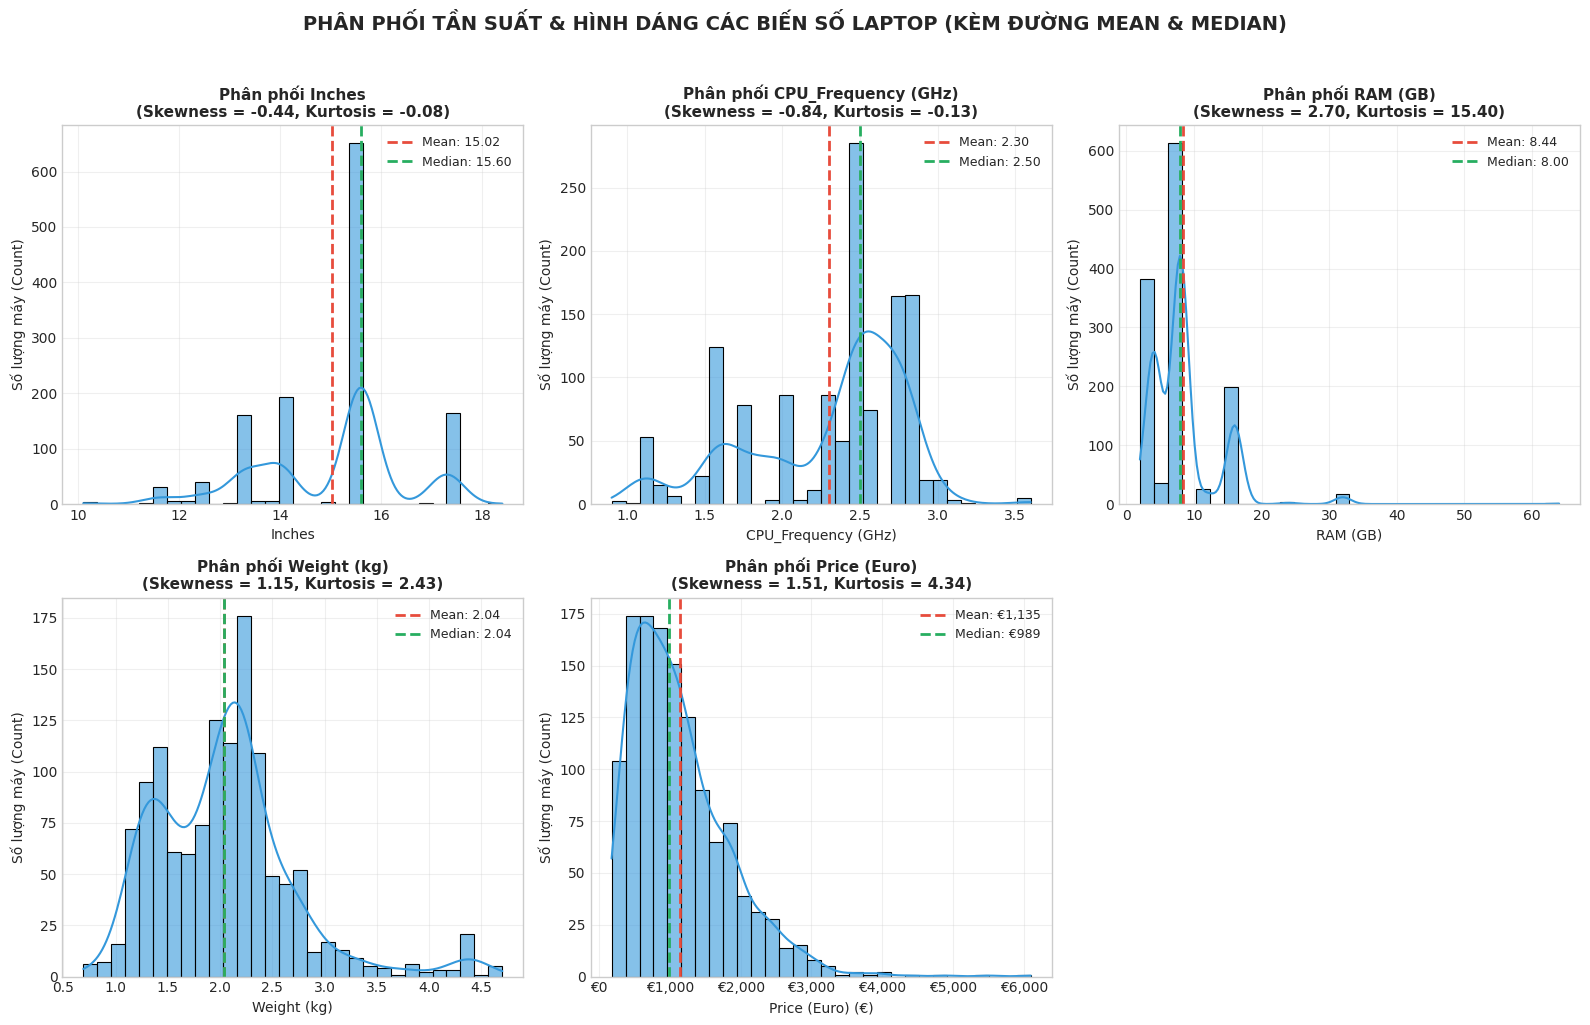

In [9]:
# 2.2 PHÂN PHỐI TẦN SUẤT & ĐỘ LỆCH (HISTOGRAM + KDE + SKEWNESS)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    data = df_raw[col].dropna()
    skew_val = data.skew()
    kurt_val = data.kurtosis()
    mean_val = data.mean()
    median_val = data.median()
    
    sns.histplot(data, kde=True, ax=axes[i], color='#3498db', edgecolor='black', alpha=0.6, bins=30)
    axes[i].set_title(f"Phân phối {col}\n(Skewness = {skew_val:.2f}, Kurtosis = {kurt_val:.2f})", fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Số lượng máy (Count)', fontsize=10)
    
    if 'Price' in col:
        axes[i].axvline(mean_val, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean: €{mean_val:,.0f}')
        axes[i].axvline(median_val, color='#27ae60', linestyle='--', linewidth=2, label=f'Median: €{median_val:,.0f}')
        axes[i].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))
        axes[i].set_xlabel(f'{col} (€)', fontsize=10)
    else:
        axes[i].axvline(mean_val, color='#e74c3c', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
        axes[i].axvline(median_val, color='#27ae60', linestyle='--', linewidth=2, label=f'Median: {median_val:.2f}')
        axes[i].set_xlabel(col, fontsize=10)
        
    axes[i].legend(loc='upper right', fontsize=9)
    axes[i].grid(alpha=0.3)

# Ẩn ô biểu đồ thứ 6 (chỉ có 5 biến số)
fig.delaxes(axes[5])
        
plt.suptitle('PHÂN PHỐI TẦN SUẤT & HÌNH DÁNG CÁC BIẾN SỐ LAPTOP (KÈM ĐƯỜNG MEAN & MEDIAN)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/fig_02_num_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

#### 2.3 Phát hiện Giá trị Ngoại lai (Boxplot & Thống kê IQR)
- Vẽ biểu đồ hộp (Boxplot) thể hiện Quartiles ($Q_1, \text{Median}, Q_3$) và phát hiện các điểm dị biệt nằm ngoài dải $[Q_1 - 1.5 \times \text{IQR}, Q_3 + 1.5 \times \text{IQR}]$.
- **Nguyên tắc phương pháp luận & Chiến lược xử lý ngoại lai**:
  + **Ngoại lai hợp lệ tự nhiên (Bảo toàn):** Các điểm ngoại lai ở biến `Price (Euro)` (giá > 2.800 €) hoặc các mức RAM cao phổ biến (16GB với 198 máy, 32GB với 17 máy) phản ánh phân khúc Gaming/Workstation cao cấp thực tế có số lượng mẫu đại diện đầy đủ, hoàn toàn không phải lỗi nhập liệu, nên được bảo toàn nguyên vẹn để phản ánh toàn vẹn thị trường.
  + **Ngoại lai cực đoan đơn lẻ ($n=1$, Loại bỏ tại Step 2):** Phát hiện duy nhất **1 mẫu laptop có RAM = 64GB** (mẫu *Asus ROG G701VO* giá 3.975 €) và **1 mẫu chạy CPU Samsung ARM Cortex** (*Samsung Chromebook Plus* giá 659 €). Vì chỉ có đúng 1 mẫu cá biệt ($n=1$), các điểm này là ngoại lai cực đoan làm méo phân phối  Do đó, theo yêu cầu kiểm soát chất lượng, cả 2 điểm ngoại lai này sẽ được loại bỏ dứt điểm tại bước Tiền xử lý .

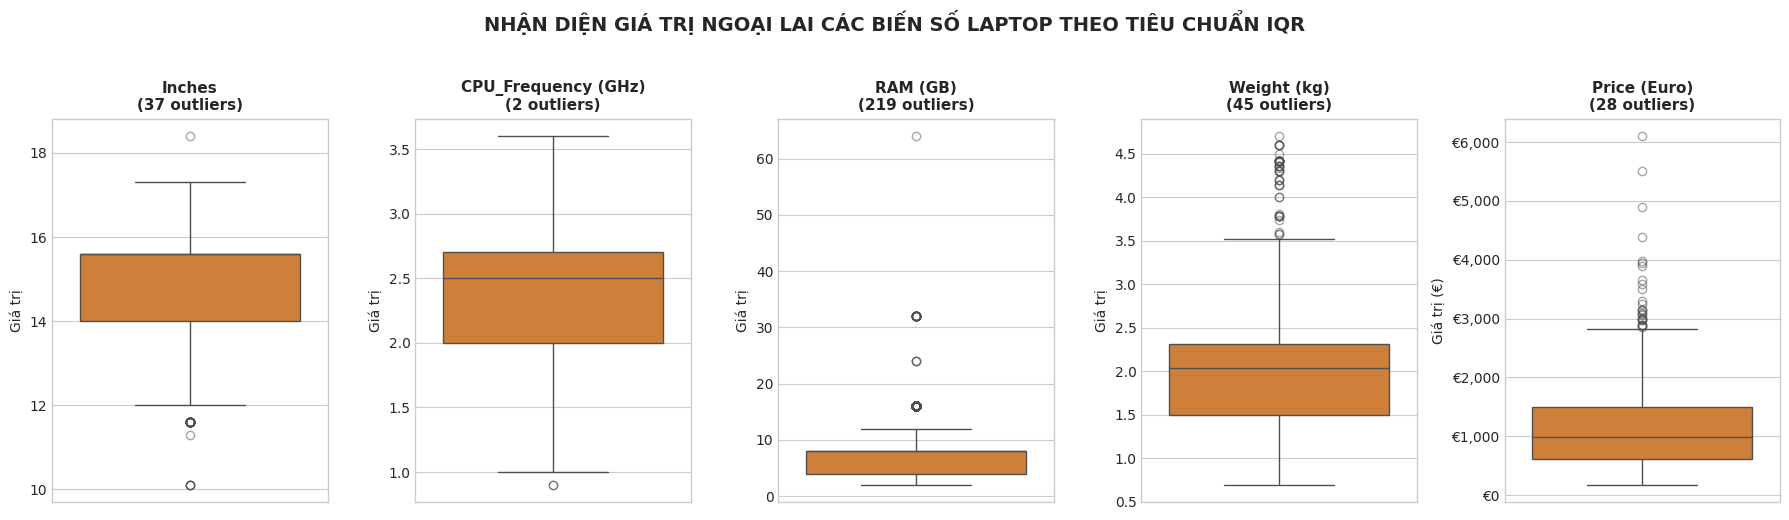

BẢNG TỔNG HỢP NGOẠI LAI (IQR METHOD):


,Biến số,Q1,Median,Q3,IQR,Số Outliers,Tỷ lệ Outliers (%)
0,Inches,14.00,15.60,15.60,1.60,37,2.90
1,CPU_Frequency (GHz),2.00,2.50,2.70,0.70,2,0.16
2,RAM (GB),4.00,8.00,8.00,4.00,219,17.18
3,Weight (kg),1.50,2.04,2.31,0.81,45,3.53
4,Price (Euro),609.00,989.00,1496.50,887.50,28,2.20


In [10]:
# 2.3 PHÁT HIỆN GIÁ TRỊ NGOẠI LAI (BOXPLOT & THỐNG KÊ IQR)
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
outlier_summary = []

for i, col in enumerate(num_cols):
    data = df_raw[col].dropna()
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    outlier_summary.append({
        'Biến số': col,
        'Q1': q1,
        'Median': data.median(),
        'Q3': q3,
        'IQR': iqr,
        'Số Outliers': len(outliers),
        'Tỷ lệ Outliers (%)': round(len(outliers) / len(df_raw) * 100, 2)
    })
    
    sns.boxplot(y=data, ax=axes[i], color='#e67e22', flierprops={'marker': 'o', 'color': 'red', 'alpha': 0.5})
    axes[i].set_title(f"{col}\n({len(outliers)} outliers)", fontsize=11, fontweight='bold')
    if 'Price' in col:
        axes[i].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))
        axes[i].set_ylabel('Giá trị (€)')
    else:
        axes[i].set_ylabel('Giá trị')

plt.suptitle('NHẬN DIỆN GIÁ TRỊ NGOẠI LAI CÁC BIẾN SỐ LAPTOP THEO TIÊU CHUẨN IQR', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('../figures/fig_03_outliers_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

df_outliers = pd.DataFrame(outlier_summary)
print("BẢNG TỔNG HỢP NGOẠI LAI (IQR METHOD):")
display(df_outliers)

#### 2.3b Đối sánh Phân phối Sau khi Lọc Ngoại lai 

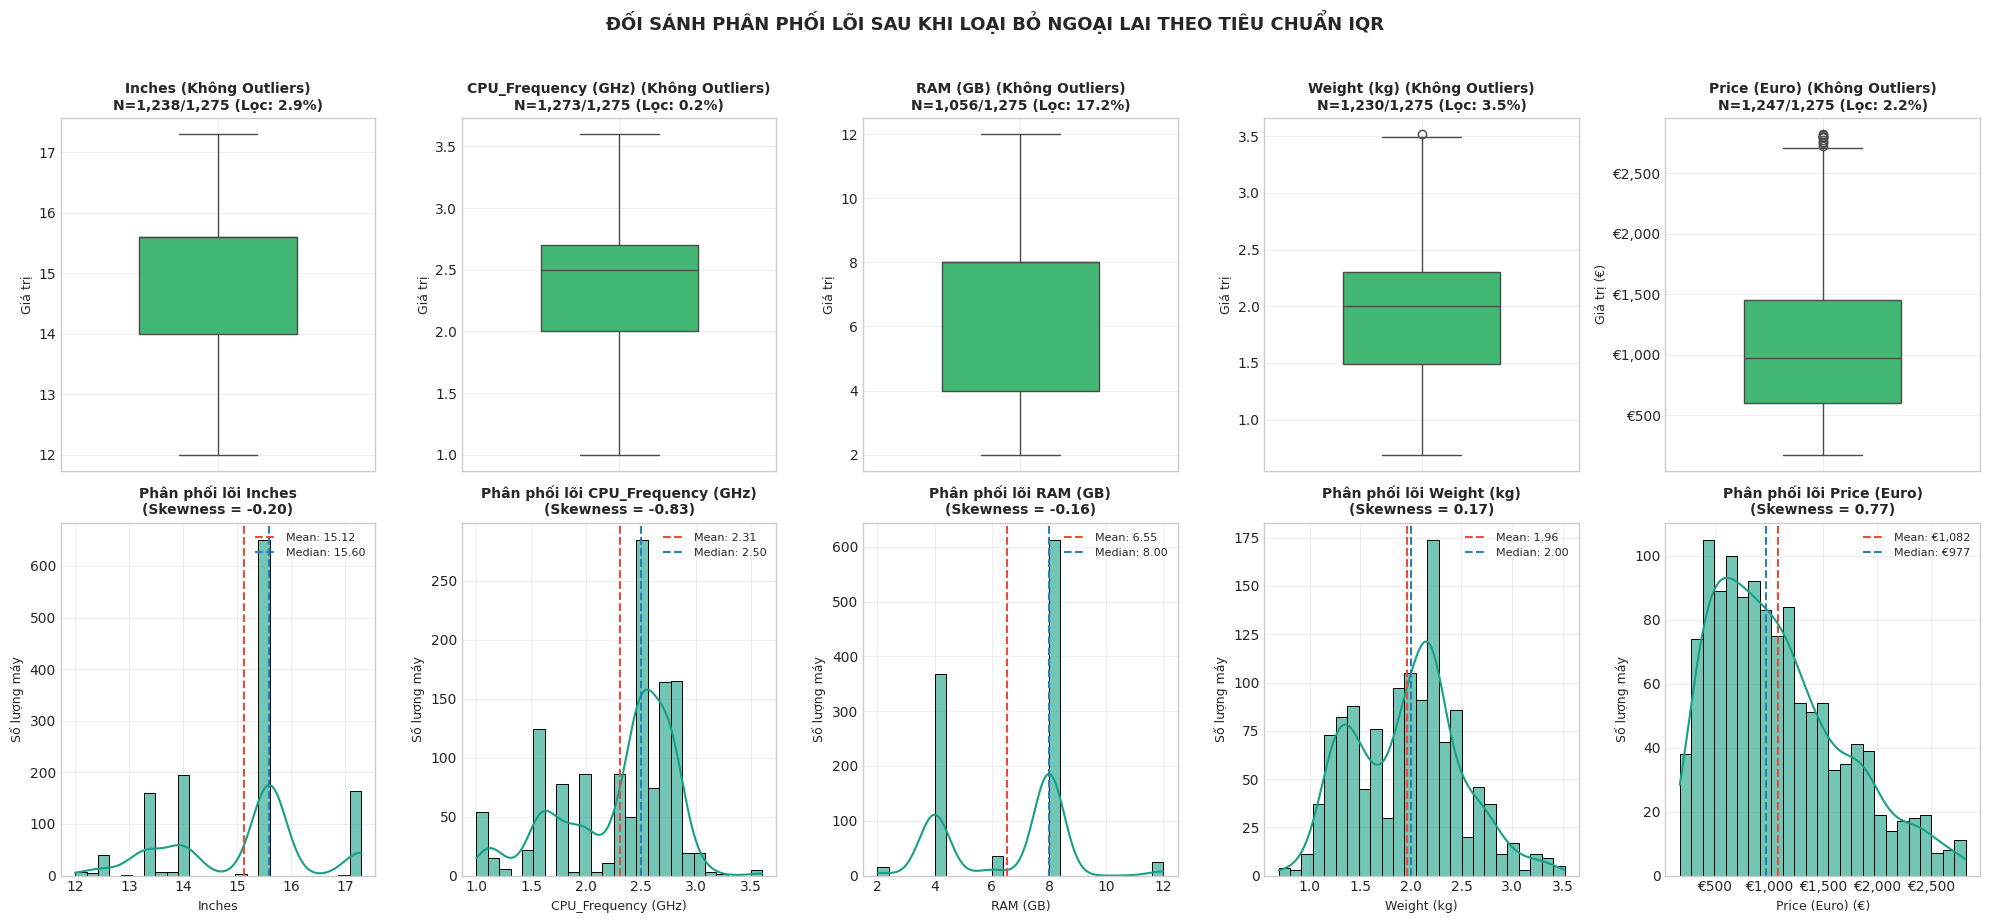

In [11]:
# 2.3b ĐỐI SÁNH PHÂN PHỐI DỮ LIỆU SAU KHI LỌC NGOẠI LAI (IQR FILTERING)
fig, axes = plt.subplots(2, 5, figsize=(20, 9))

for i, col in enumerate(num_cols):
    data = df_raw[col].dropna()
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    filtered = data[(data >= lower_bound) & (data <= upper_bound)]
    rem_pct = (1 - len(filtered) / len(data)) * 100
    mean_f = filtered.mean()
    med_f = filtered.median()
    skew_f = filtered.skew()
    
    # Hàng 1: Boxplot sau lọc ngoại lai
    sns.boxplot(y=filtered, ax=axes[0, i], color='#2ecc71', width=0.5)
    axes[0, i].set_title(f"{col} (Không Outliers)\nN={len(filtered):,}/{len(data):,} (Lọc: {rem_pct:.1f}%)", fontsize=10, fontweight='bold')
    if 'Price' in col:
        axes[0, i].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))
        axes[0, i].set_ylabel('Giá trị (€)', fontsize=9)
    else:
        axes[0, i].set_ylabel('Giá trị', fontsize=9)
    axes[0, i].grid(alpha=0.3)
    
    # Hàng 2: Histogram + KDE sau lọc ngoại lai
    sns.histplot(filtered, kde=True, ax=axes[1, i], color='#16a085', edgecolor='black', alpha=0.6, bins=25)
    axes[1, i].set_title(f"Phân phối lõi {col}\n(Skewness = {skew_f:.2f})", fontsize=10, fontweight='bold')
    axes[1, i].set_ylabel('Số lượng máy', fontsize=9)
    
    if 'Price' in col:
        axes[1, i].axvline(mean_f, color='#e74c3c', linestyle='--', linewidth=1.5, label=f'Mean: €{mean_f:,.0f}')
        axes[1, i].axvline(med_f, color='#2980b9', linestyle='--', linewidth=1.5, label=f'Median: €{med_f:,.0f}')
        axes[1, i].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))
        axes[1, i].set_xlabel(f'{col} (€)', fontsize=9)
    else:
        axes[1, i].axvline(mean_f, color='#e74c3c', linestyle='--', linewidth=1.5, label=f'Mean: {mean_f:.2f}')
        axes[1, i].axvline(med_f, color='#2980b9', linestyle='--', linewidth=1.5, label=f'Median: {med_f:.2f}')
        axes[1, i].set_xlabel(col, fontsize=9)
        
    axes[1, i].legend(loc='upper right', fontsize=8)
    axes[1, i].grid(alpha=0.3)

plt.suptitle('ĐỐI SÁNH PHÂN PHỐI LÕI SAU KHI LOẠI BỎ NGOẠI LAI THEO TIÊU CHUẨN IQR', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

#### 2.4 Phân bố Tần suất Biến Phân loại Thô (Countplot)


C:\Users\Admin\AppData\Local\Temp\ipykernel_5736\1306871438.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_raw, y='Company', order=company_order, palette='mako')


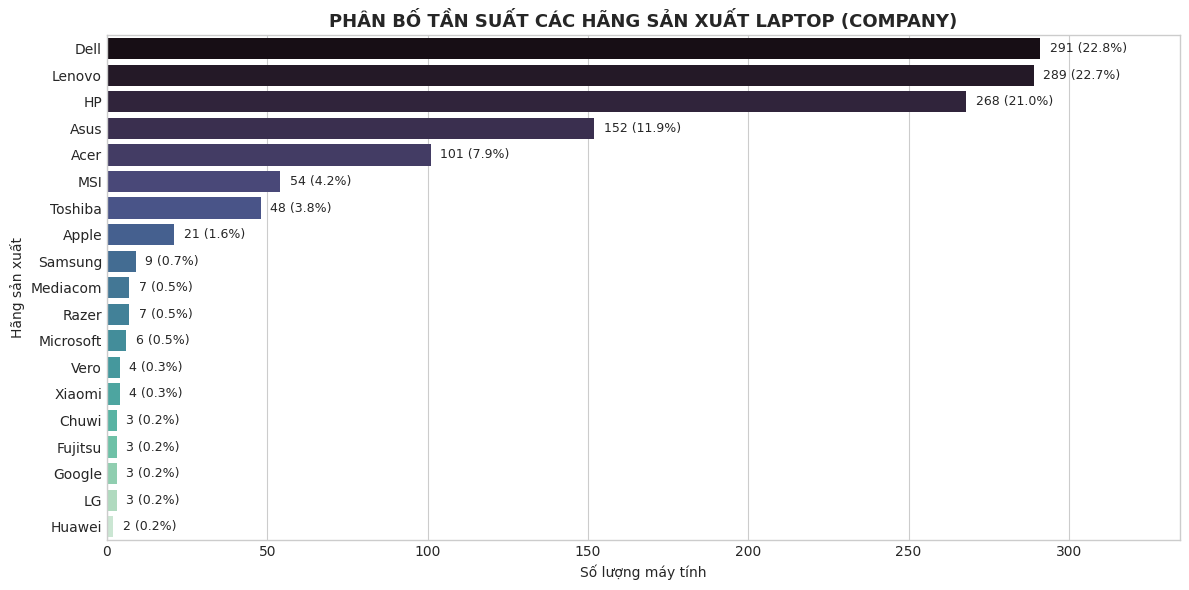

C:\Users\Admin\AppData\Local\Temp\ipykernel_5736\1306871438.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_raw, y=col, order=order, ax=axes[i], palette='viridis')
C:\Users\Admin\AppData\Local\Temp\ipykernel_5736\1306871438.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_raw, y=col, order=order, ax=axes[i], palette='viridis')
C:\Users\Admin\AppData\Local\Temp\ipykernel_5736\1306871438.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_raw, y=col, order=order, ax=axes[i], palette='viridis')
C:\Users\A

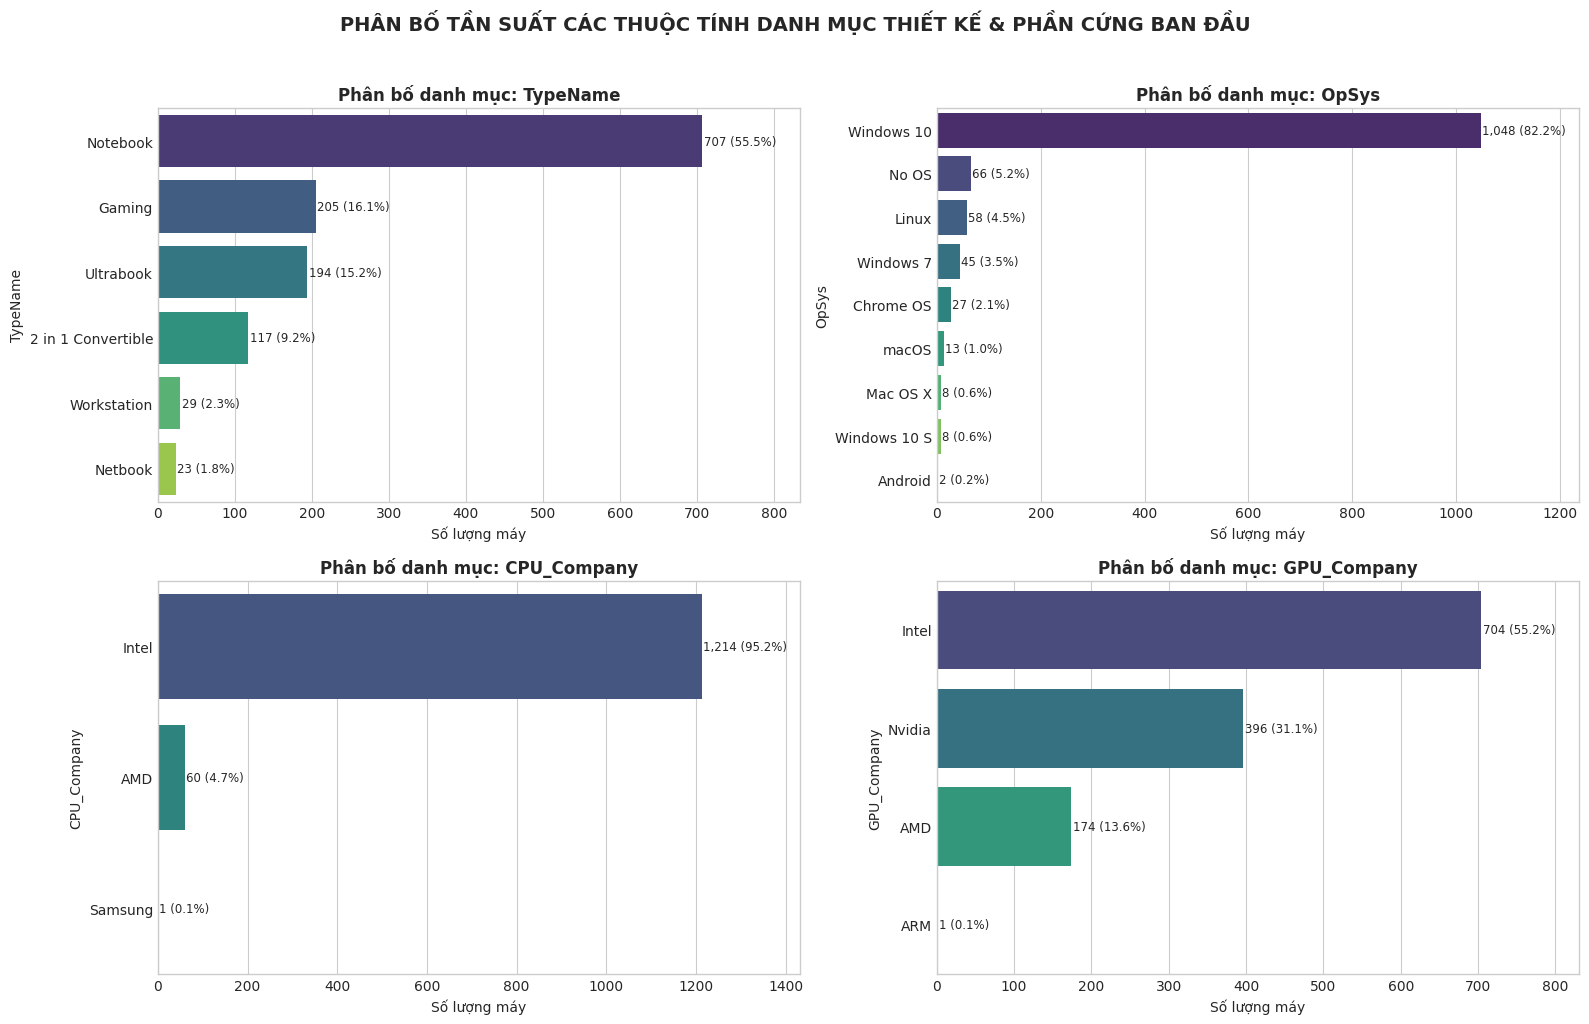

In [12]:
# Hình 1: Phân bố thương hiệu Laptop (Company)
plt.figure(figsize=(12, 6))
company_order = df_raw['Company'].value_counts().index
ax = sns.countplot(data=df_raw, y='Company', order=company_order, palette='mako')
plt.title('PHÂN BỐ TẦN SUẤT CÁC HÃNG SẢN XUẤT LAPTOP (COMPANY)', fontsize=13, fontweight='bold')
plt.xlabel('Số lượng máy tính', fontsize=10)
plt.ylabel('Hãng sản xuất', fontsize=10)

for p in ax.patches:
    width = p.get_width()
    pct = width / len(df_raw) * 100
    ax.annotate(f'{int(width):,} ({pct:.1f}%)', (width + 3, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=9)

plt.xlim(0, max(df_raw['Company'].value_counts()) * 1.15)
plt.tight_layout()
plt.savefig('../figures/fig_04_company_countplot.png', dpi=300, bbox_inches='tight')
plt.show()

# Hình 2: Lưới 2x2 cho TypeName, OpSys, CPU_Company, GPU_Company
cat_features = ['TypeName', 'OpSys', 'CPU_Company', 'GPU_Company']
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    order = df_raw[col].value_counts().index
    sns.countplot(data=df_raw, y=col, order=order, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Phân bố danh mục: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Số lượng máy', fontsize=10)
    axes[i].set_ylabel(col, fontsize=10)
    
    for p in axes[i].patches:
        w = p.get_width()
        pct = w / len(df_raw) * 100
        axes[i].annotate(f'{int(w):,} ({pct:.1f}%)', (w + 2, p.get_y() + p.get_height() / 2),
                         ha='left', va='center', fontsize=8.5)
    axes[i].set_xlim(0, max(df_raw[col].value_counts()) * 1.18)

plt.suptitle('PHÂN BỐ TẦN SUẤT CÁC THUỘC TÍNH DANH MỤC THIẾT KẾ & PHẦN CỨNG BAN ĐẦU', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/fig_05_hardware_categories_countplot.png', dpi=300, bbox_inches='tight')
plt.show()

---
# PHẦN III: TỔNG KẾT 

### Kết luận quan trọng từ EDA 1 (Khám phá phân phối dữ liệu thô):
1. **Chất lượng dữ liệu ban đầu**: Hoàn chỉnh 100%, không khuyết thiếu ($0\text{ Missing Values}$), không trùng lặp ($0\text{ Duplicates}$).
2. **Hình dáng biến mục tiêu `Price (Euro)`**: Bị lệch phải mạnh ($Skew = 1.511$) và đuôi dày ($Kurt = 4.341$), đòi hỏi phải thực hiện biến đổi Log-transform ở giai đoạn sau.
3. **Phát hiện & Định hướng xử lý Ngoại lai (Outliers)**:
   
   - *Loại bỏ ngoại lai cực đoan đơn lẻ ($n=1$):* Duy nhất 1 mẫu **RAM = 64GB** (*Asus ROG G701VO*) và 1 mẫu **Samsung ARM Processor** được chuyển giao để loại bỏ dứt điểm trong Notebook 02 nhằm tránh làm sai lệch mô hình học máy và khoảng phân tán.
4. **Vấn đề cần giải quyết**: Các cột `ScreenResolution`, `Memory`, `CPU_Type`, `GPU_Type` chứa văn bản hỗn hợp không thể tính toán trực tiếp, cần được bóc tách bằng Feature Engineering.
